# RFM Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/processed/retail_cleaned.csv",
    parse_dates=["InvoiceDate"]
)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (779425, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [2]:
print("First Transaction Date:", df["InvoiceDate"].min())
print("Last Transaction Date:", df["InvoiceDate"].max())
print("Unique Customers:", df["Customer ID"].nunique())
print("Unique Invoices:", df["Invoice"].nunique())

First Transaction Date: 2009-12-01 07:45:00
Last Transaction Date: 2011-12-09 12:50:00
Unique Customers: 5878
Unique Invoices: 36969


In [3]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

print("RFM Reference Date:", snapshot_date)

RFM Reference Date: 2011-12-10 12:50:00


In [5]:
#Calculate R, F and M for each customer
rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

display(rfm.head(10))

,Customer ID,Recency,Frequency,Monetary
0,12346,326,12,77556.46
1,12347,2,8,4921.53
2,12348,75,5,2019.40
3,12349,19,4,4428.69
4,12350,310,1,334.40
5,12351,375,1,300.93
6,12352,36,10,2849.84
7,12353,204,2,406.76
8,12354,232,1,1079.40
9,12355,214,2,947.61


In [6]:
print("Total customers:", len(rfm))

display(rfm[["Recency", "Frequency", "Monetary"]].describe())

Total customers: 5878


,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000
mean,201.331916,6.289384,2955.904095
std,209.338707,13.009406,14440.852688
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,342.280000
50%,96.000000,3.000000,867.740000
75%,380.000000,7.000000,2248.305000
max,739.000000,398.000000,580987.040000


In [7]:
# Assign scores from 1 to 5

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

display(rfm.head(10))

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346,326,12,77556.46,2,5,5
1,12347,2,8,4921.53,5,4,5
2,12348,75,5,2019.40,3,4,4
3,12349,19,4,4428.69,5,3,5
4,12350,310,1,334.40,2,1,2
5,12351,375,1,300.93,2,1,2
6,12352,36,10,2849.84,4,5,4
7,12353,204,2,406.76,2,2,2
8,12354,232,1,1079.40,2,1,3
9,12355,214,2,947.61,2,2,3


In [8]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

display(rfm.head(10))

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,12,77556.46,2,5,5,255
1,12347,2,8,4921.53,5,4,5,545
2,12348,75,5,2019.40,3,4,4,344
3,12349,19,4,4428.69,5,3,5,535
4,12350,310,1,334.40,2,1,2,212
5,12351,375,1,300.93,2,1,2,212
6,12352,36,10,2849.84,4,5,4,454
7,12353,204,2,406.76,2,2,2,222
8,12354,232,1,1079.40,2,1,3,213
9,12355,214,2,947.61,2,2,3,223


In [10]:
#Create customer segments
conditions = [
    (rfm["R_Score"] >= 4) & (rfm["F_Score"] >= 4) & (rfm["M_Score"] >= 4),

    (rfm["R_Score"] >= 3) & (rfm["F_Score"] >= 4),

    (rfm["R_Score"] >= 4) & (rfm["F_Score"].between(2, 3)),

    (rfm["R_Score"] == 5) & (rfm["F_Score"] == 1),

    (rfm["R_Score"] <= 2) & (rfm["F_Score"] >= 3),

    (rfm["R_Score"] <= 2) & (rfm["F_Score"] <= 2)
]

segments = [
    "Champions",
    "Loyal Customers",
    "Potential Loyalists",
    "New Customers",
    "At Risk",
    "Hibernating"
]

rfm["Segment"] = np.select(
    conditions,
    segments,
    default="Others"
)

display(rfm.head(10))

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,12,77556.46,2,5,5,255,At Risk
1,12347,2,8,4921.53,5,4,5,545,Champions
2,12348,75,5,2019.40,3,4,4,344,Loyal Customers
3,12349,19,4,4428.69,5,3,5,535,Potential Loyalists
4,12350,310,1,334.40,2,1,2,212,Hibernating
5,12351,375,1,300.93,2,1,2,212,Hibernating
6,12352,36,10,2849.84,4,5,4,454,Champions
7,12353,204,2,406.76,2,2,2,222,Hibernating
8,12354,232,1,1079.40,2,1,3,213,Hibernating
9,12355,214,2,947.61,2,2,3,223,Hibernating


In [11]:
#Analyse the number of customers in each segment
segment_summary = rfm.groupby("Segment").agg(
    Customers=("Customer ID", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).reset_index()

segment_summary["Customer_Percentage"] = (
    segment_summary["Customers"] / len(rfm) * 100
).round(2)

segment_summary = segment_summary.sort_values(
    "Customers", ascending=False
)

display(segment_summary)

,Segment,Customers,Average_Recency,Average_Frequency,Average_Monetary,Total_Revenue,Customer_Percentage
2,Hibernating,1526,458.749672,1.252949,429.518140,6.554447e+05,25.96
1,Champions,1289,19.719162,17.146625,9169.609678,1.181963e+07,21.93
0,At Risk,825,368.882424,4.941818,1927.738887,1.590385e+06,14.04
5,Others,765,98.596078,1.934641,758.151690,5.799860e+05,13.01
6,Potential Loyalists,711,25.616034,2.592124,1145.294502,8.143044e+05,12.10
3,Loyal Customers,708,83.933616,7.769774,2677.445445,1.895631e+06,12.04
4,New Customers,54,10.500000,1.000000,359.746667,1.942632e+04,0.92


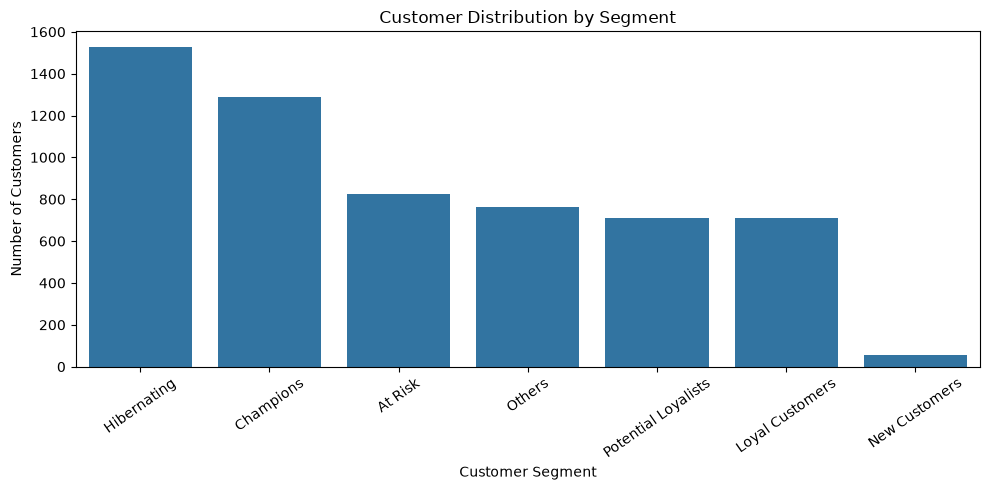

In [15]:
#Customer distribution by segment
plt.figure(figsize=(10, 5))

sns.barplot(
    data=segment_summary,
    x="Segment",
    y="Customers"
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

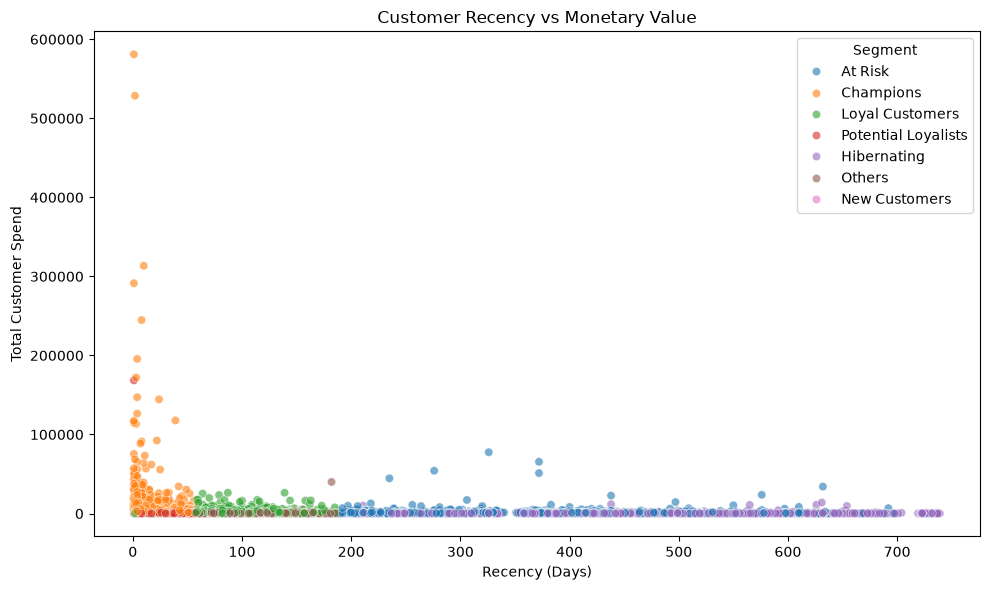

In [16]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Segment",
    alpha=0.6
)

plt.title("Customer Recency vs Monetary Value")
plt.xlabel("Recency (Days)")
plt.ylabel("Total Customer Spend")
plt.tight_layout()
plt.show()

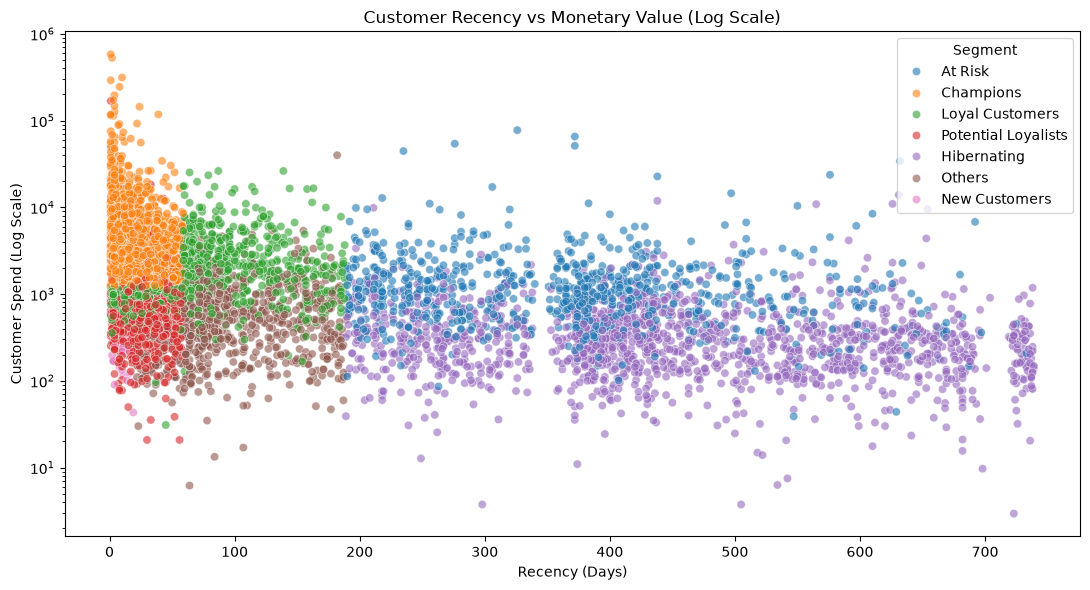

In [17]:
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Segment",
    alpha=0.6
)

plt.yscale("log")

plt.title("Customer Recency vs Monetary Value (Log Scale)")
plt.xlabel("Recency (Days)")
plt.ylabel("Customer Spend (Log Scale)")

plt.tight_layout()
plt.show()

In [18]:
rfm.to_csv(
    "../data/processed/customer_rfm.csv",
    index=False
)

segment_summary.to_csv(
    "../data/processed/segment_summary.csv",
    index=False
)

print("RFM customer data and segment summary saved successfully!")

RFM customer data and segment summary saved successfully!
